<a href="https://colab.research.google.com/github/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/blob/main/Week_4/Training_dengan_5_Model_Berbeda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Buka UCI Machine Learning Repository
2. Pilih menu dataset
3. Cari dataset Diabetes
4. Pilih Early Stage Diabetes Risk Prediction

https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset

In [1]:
#@title 5. Klik tombol download
import urllib.request
import zipfile
import os

# URL of the dataset
url = 'https://archive.ics.uci.edu/static/public/529/early+stage+diabetes+risk+prediction+dataset.zip'
zip_path = 'early_stage_diabetes.zip'
extract_dir = 'early_stage_diabetes'

# Download the file
print("Downloading dataset...")
urllib.request.urlretrieve(url, zip_path)

# Extract the file
print("Extracting dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# List the extracted files
print("Extracted files:")
print(os.listdir(extract_dir))

Extracting dataset...
Extracted files:
['diabetes_data_upload.csv']


In [2]:
#@title 6. File zip diekstrak, akan muncul file csv
import pandas as pd

# Load the dataset
df = pd.read_csv('early_stage_diabetes/diabetes_data_upload.csv')

# Display the shape and first 5 rows
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (520, 17)


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


### 7. Klasifikasi dan Evaluasi Model

Kita akan memproses data terlebih dahulu dengan melakukan encoding label (kategorikal menjadi numerik), lalu melatih model klasifikasi (Random Forest) dan mengevaluasinya menggunakan 10-Fold Cross Validation serta visualisasi evaluasi.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import train_test_split

# 1. Preprocessing Data
df_processed = df.copy()
label_encoders = {}

# Encode categorical columns to numerical (0 or 1)
for col in df_processed.columns:
    if df_processed[col].dtype == 'object':
        le = LabelEncoder()
        df_processed[col] = le.fit_transform(df_processed[col])
        label_encoders[col] = le

# Split features and target
X = df_processed.drop(columns=['class'])
y = df_processed['class']

# Tampilkan hasil preprocessing singkat
display(df_processed.head())

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


In [4]:
# 2. 10-Fold Cross-Validation dan Metrik Evaluasi
model = RandomForestClassifier(random_state=42)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Tentukan metrik yang ingin dihitung
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
scores = cross_validate(model, X, y, cv=cv, scoring=scoring)

print("--- HASIL 10-FOLD CROSS VALIDATION ---")
print(f"a. Akurasi   : {np.mean(scores['test_accuracy']):.4f} (+/- {np.std(scores['test_accuracy']):.4f})")
print(f"   Presisi   : {np.mean(scores['test_precision']):.4f} (+/- {np.std(scores['test_precision']):.4f})")
print(f"   Recall    : {np.mean(scores['test_recall']):.4f} (+/- {np.std(scores['test_recall']):.4f})")
print(f"   F1-Score  : {np.mean(scores['test_f1']):.4f} (+/- {np.std(scores['test_f1']):.4f})")
print(f"   AUC       : {np.mean(scores['test_roc_auc']):.4f} (+/- {np.std(scores['test_roc_auc']):.4f})")

--- HASIL 10-FOLD CROSS VALIDATION ---
a. Akurasi   : 0.9865 (+/- 0.0173)
   Presisi   : 0.9880 (+/- 0.0198)
   Recall    : 0.9906 (+/- 0.0200)
   F1-Score  : 0.9891 (+/- 0.0141)
   AUC       : 0.9992 (+/- 0.0016)


--- RINCIAN PEMBAGIAN DATA ---
Total Data Sebelum Split : 520 data
Jumlah Data Training (80%): 416 data
Jumlah Data Testing  (20%): 104 data



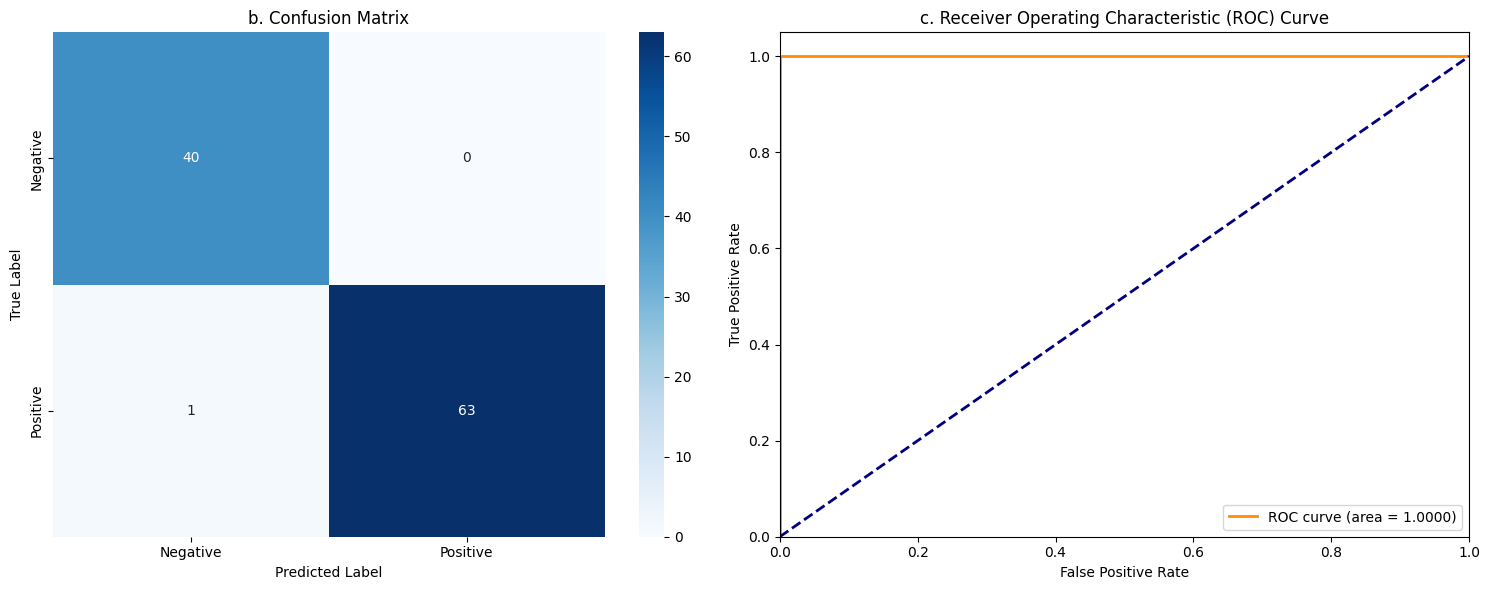

In [6]:
# 3. Membuat Visualisasi Grafik ROC dan Confusion Matrix
# Kita bagi data menjadi train-test split untuk visualisasi representatif kurva dan matriks
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# b. Grafik Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
ax[0].set_title('b. Confusion Matrix')
ax[0].set_xlabel('Predicted Label')
ax[0].set_ylabel('True Label')

# c. Grafik ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('c. Receiver Operating Characteristic (ROC) Curve')
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 8. Perbandingan Multi-Model: Random Forest, KNN, Decision Tree, SVM, dan Naive Bayes

Bagian ini melakukan evaluasi komparatif dari 5 algoritma klasifikasi menggunakan teknik **10-Fold Cross-Validation** (Stratified) dan menampilkan hasilnya dalam bentuk tabel perbandingan ringkas.

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd

# 1. Definisikan Model yang Akan Dibandingkan
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Naive Bayes': GaussianNB()
}

# Wadah untuk menampung hasil rata-rata
comparison_results = []

# 2. Lakukan 10-Fold Cross-Validation untuk Setiap Model
for name, model_obj in models.items():
    scores_cv = cross_validate(model_obj, X, y, cv=cv, scoring=scoring)

    # Ambil rata-rata dari setiap metrik
    comparison_results.append({
        'Model': name,
        'Akurasi': np.mean(scores_cv['test_accuracy']),
        'Presisi': np.mean(scores_cv['test_precision']),
        'Recall': np.mean(scores_cv['test_recall']),
        'F1-Score': np.mean(scores_cv['test_f1']),
        'AUC': np.mean(scores_cv['test_roc_auc'])
    })

# 3. Buat DataFrame Perbandingan
df_comparison = pd.DataFrame(comparison_results)
print("--- TABEL PERBANDINGAN MODEL (10-FOLD CV) ---")
display(df_comparison.style.highlight_max(axis=0, color='green', subset=['Akurasi', 'Presisi', 'Recall', 'F1-Score', 'AUC']))

--- TABEL PERBANDINGAN MODEL (10-FOLD CV) ---


,Model,Akurasi,Presisi,Recall,F1-Score,AUC
0,Random Forest,0.986538,0.987962,0.990625,0.989080,0.999219
1,KNN,0.878846,0.953847,0.846875,0.894857,0.959687
2,Decision Tree,0.973077,0.981528,0.975000,0.978072,0.972500
3,SVM,0.615385,0.615385,1.000000,0.761905,0.895781
4,Naive Bayes,0.890385,0.908360,0.918750,0.911269,0.956406


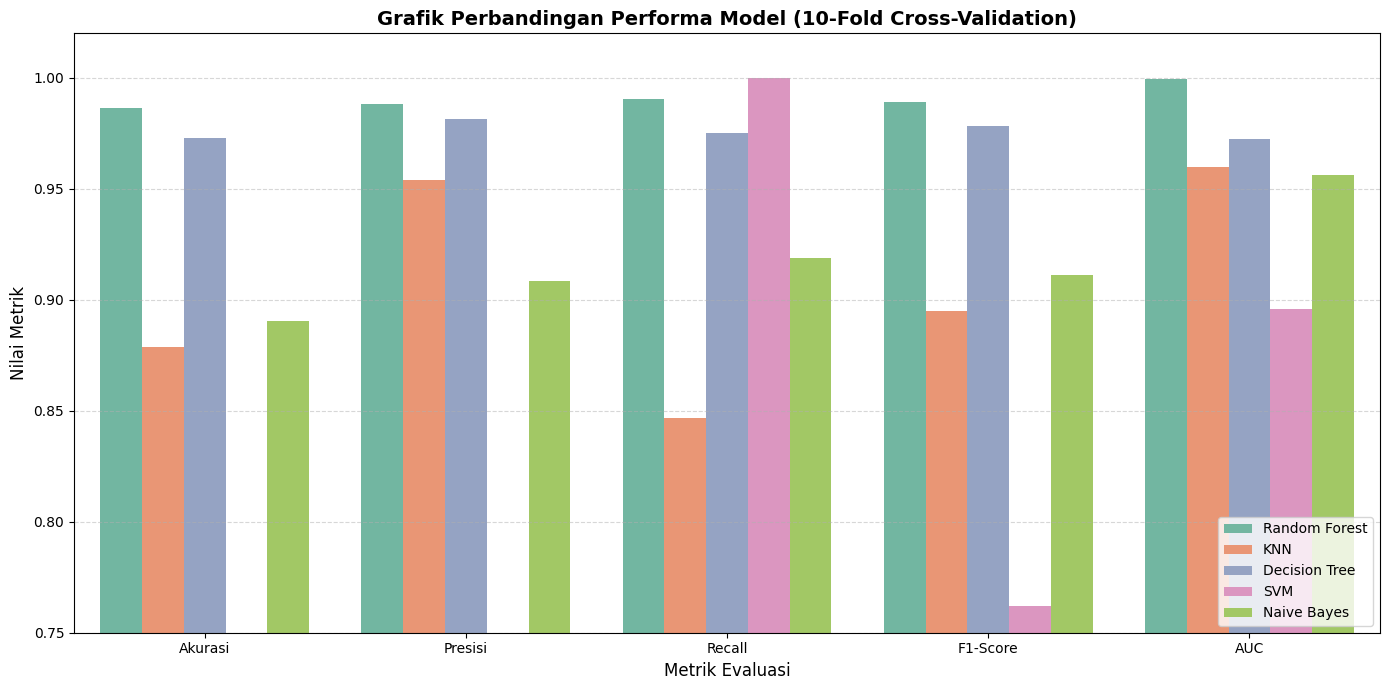

In [14]:
# 4. Visualisasi Grafik Perbandingan Metrik Antar Model
df_melted = df_comparison.melt(id_vars='Model', var_name='Metrik', value_name='Nilai')

plt.figure(figsize=(14, 7))
sns.barplot(data=df_melted, x='Metrik', y='Nilai', hue='Model', palette='Set2')
plt.title('Grafik Perbandingan Performa Model (10-Fold Cross-Validation)', fontsize=14, fontweight='bold')
plt.xlabel('Metrik Evaluasi', fontsize=12)
plt.ylabel('Nilai Metrik', fontsize=12)
plt.ylim(0.75, 1.02)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 9. Perbandingan Kurva ROC (Receiver Operating Characteristic) Antar Model

Untuk melengkapi analisis komparatif, berikut ini adalah grafik yang membandingkan kurva ROC beserta nilai AUC (Area Under Curve) masing-masing model yang dilatih pada 80% data training dan dievaluasi pada 20% data testing.

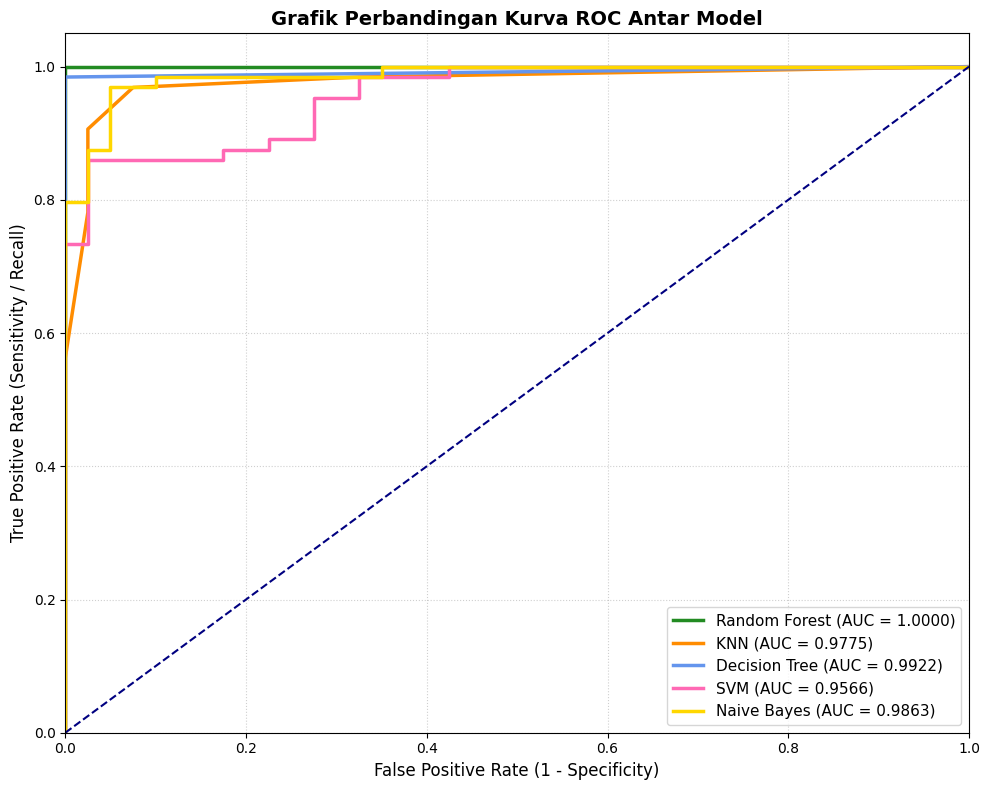

In [16]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

# Definisikan warna yang berbeda untuk setiap model
colors = {
    'Random Forest': 'forestgreen',
    'KNN': 'darkorange',
    'Decision Tree': 'cornflowerblue',
    'SVM': 'hotpink',
    'Naive Bayes': 'gold'
}

# Lakukan fitting dan plotting ROC untuk setiap model
for name, model_obj in models.items():
    # Fit menggunakan data training
    model_obj.fit(X_train, y_train)

    # Dapatkan probabilitas prediksi untuk kelas positif (1)
    if hasattr(model_obj, "predict_proba"):
        y_proba_model = model_obj.predict_proba(X_test)[:, 1]
    else:
        # Antisipasi jika ada model yang tidak memiliki predict_proba (meskipun semua di atas punya)
        y_proba_model = model_obj.decision_function(X_test)

    # Hitung False Positive Rate dan True Positive Rate
    fpr_m, tpr_m, _ = roc_curve(y_test, y_proba_model)
    roc_auc_m = auc(fpr_m, tpr_m)

    # Plot kurva ROC
    plt.plot(fpr_m, tpr_m, color=colors[name], lw=2.5,
             label=f'{name} (AUC = {roc_auc_m:.4f})')

# Plot garis diagonal referensi (random classifier)
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')

# Atur spesifikasi grafik
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Grafik Perbandingan Kurva ROC Antar Model', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 10. Perbandingan Confusion Matrix Antar Model

Berikut adalah visualisasi matriks kebingungan (*Confusion Matrix*) untuk masing-masing dari kelima model yang dilatih pada data training (80%) dan dievaluasi pada data uji (20%) untuk melihat rincian prediksi benar dan salah secara detail.

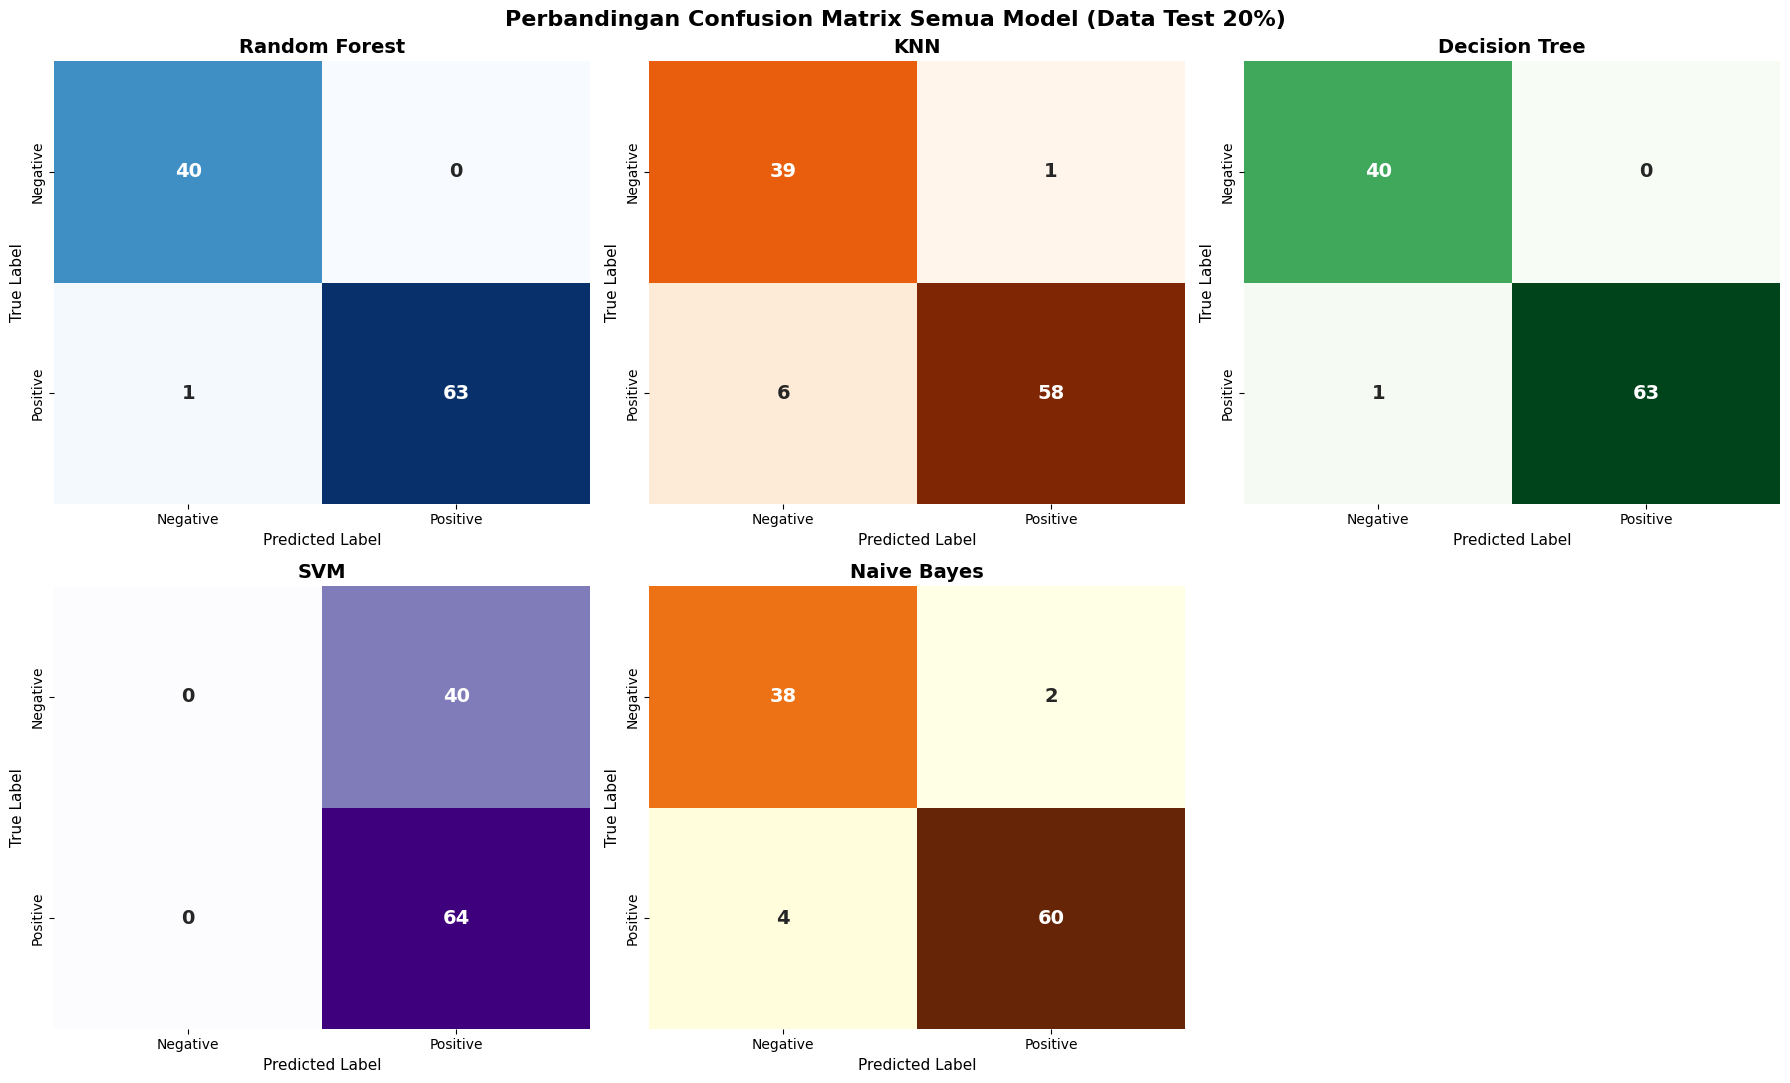

In [17]:
from sklearn.metrics import confusion_matrix

# Mengatur tata letak subplot (2 baris, 3 kolom)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel() # Meratakan matriks axes menjadi array 1 dimensi

# Definisikan skema warna (colormap) yang berbeda untuk variasi visualisasi setiap model
colormaps = {
    'Random Forest': 'Blues',
    'KNN': 'Oranges',
    'Decision Tree': 'Greens',
    'SVM': 'Purples',
    'Naive Bayes': 'YlOrBr'
}

# Latih setiap model dan plot Confusion Matrix masing-masing
for i, (name, model_obj) in enumerate(models.items()):
    # Latih model
    model_obj.fit(X_train, y_train)
    # Prediksi hasil label uji
    y_pred_model = model_obj.predict(X_test)

    # Hitung Confusion Matrix
    cm_model = confusion_matrix(y_test, y_pred_model)

    # Plot Heatmap di subplot yang sesuai
    sns.heatmap(cm_model, annot=True, fmt='d', cmap=colormaps[name], ax=axes[i],
                xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'],
                cbar=False, annot_kws={'size': 14, 'weight': 'bold'})

    axes[i].set_title(f'{name}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Predicted Label', fontsize=11)
    axes[i].set_ylabel('True Label', fontsize=11)

# Sembunyikan subplot ke-6 (indeks 5) yang tidak terpakai
axes[5].axis('off')

plt.suptitle('Perbandingan Confusion Matrix Semua Model (Data Test 20%)', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()